# ANA-069 — Interaction strength, global statistics and adaptive search

EXP-065 / RUN-175, attempt 2 (Slurm 2322). Non-production paired sweep on GB1 and TrpB, completed 8 October 2026 in 558 seconds. This notebook regenerates all five figures and audit tables from the frozen RUN bundle. It examines useful model regimes, without numerical acceptance gates or fitting specific empirical interactions.

**Design.** Six strengths $r=0,0.5,1,2,4,8$ share the same additive and interaction fields within each seed. Rank, interaction-order mixture, empirical masks and observation pools are fixed. Only the global readout is calibrated to the original quantiles, local SD and floor-mass objective. The r=0 and r=4 settings retain RUN-172 parameters. WHT, diminishing returns and graph dynamics are diagnostic outcomes. Sixteen reused and eight fresh seeds are displayed separately. The fresh seeds test generation variability, not independence of the inspected empirical landscapes.

**Reproduction.** Restore `data/processed/aggregate-thermodynamic-gnk-calibration/RUN-175.dvc`; install `notebooks/requirements.txt`; run `python notebooks/execute.py` from this analysis directory, or execute this notebook top to bottom. The saved source and inputs are in the RUN bundle; no queue access is needed to regenerate figures.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'AIM.md').exists())
ana = root / 'analyses/2026-10-08_ANA-069_run-175-interaction-strength-global-statistics-and-adaptive-walks'
sys.path.insert(0, str(ana / 'notebooks'))
import analysis_tools as analysis
import plot_tools as plots
for directory in [analysis.TABLES, analysis.FIGURES]:
    directory.mkdir(exist_ok=True)
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


## Computation checks
Hashes verify all recorded output, input and source files. Every r=0/r=4 comparison present in ANA-068 is replayed; a separate implementation recomputes the calibration objective and Walsh powers. These establish implementation consistency, not biological adequacy.

In [2]:
audit = analysis.verify()
display(pd.Series(audit, name='Verified result').to_frame())
graph, cubes, fits, latent = analysis.load()

,Verified result
output_hashes,139
input_hashes,24
source_hashes,16
anchor_graph_rows_replayed,390
maximum_anchor_difference,0.0
calibration_objectives_recomputed,24
field_nodes_replayed,36432
independent_wht_summary_rows,1732
small_graph_cases,20
settings,24


## Figure 1 | Weaker interactions lengthen walks, but length is not the whole search problem.

No added observation noise. Stars represent empirical maps; solid circles and faint points represent fresh-seed medians and individual seeds. Open squares show the reused-seed medians. Each walk starts uniformly over retained nodes and moves until no improving neighbor remains; the top-1% threshold belongs to each landscape. The primary tolerance is 0.001 times the frozen empirical calibration range. Uniform uphill chooses among improving neighbors uniformly; greedy chooses the fittest improving neighbor, averaging ties. Exact dynamic programming computes expectations, rather than sampling walks.

GB1 r=0.5 has 8.20 expected uniform substitutions and 95.4% upper-1% success (empirical: 9.74 and 93.5%). TrpB r=1 has 8.96 substitutions but 99.5% success (empirical: 8.59 and 65.0%). A near-matching walk length can therefore conceal a much easier search problem.

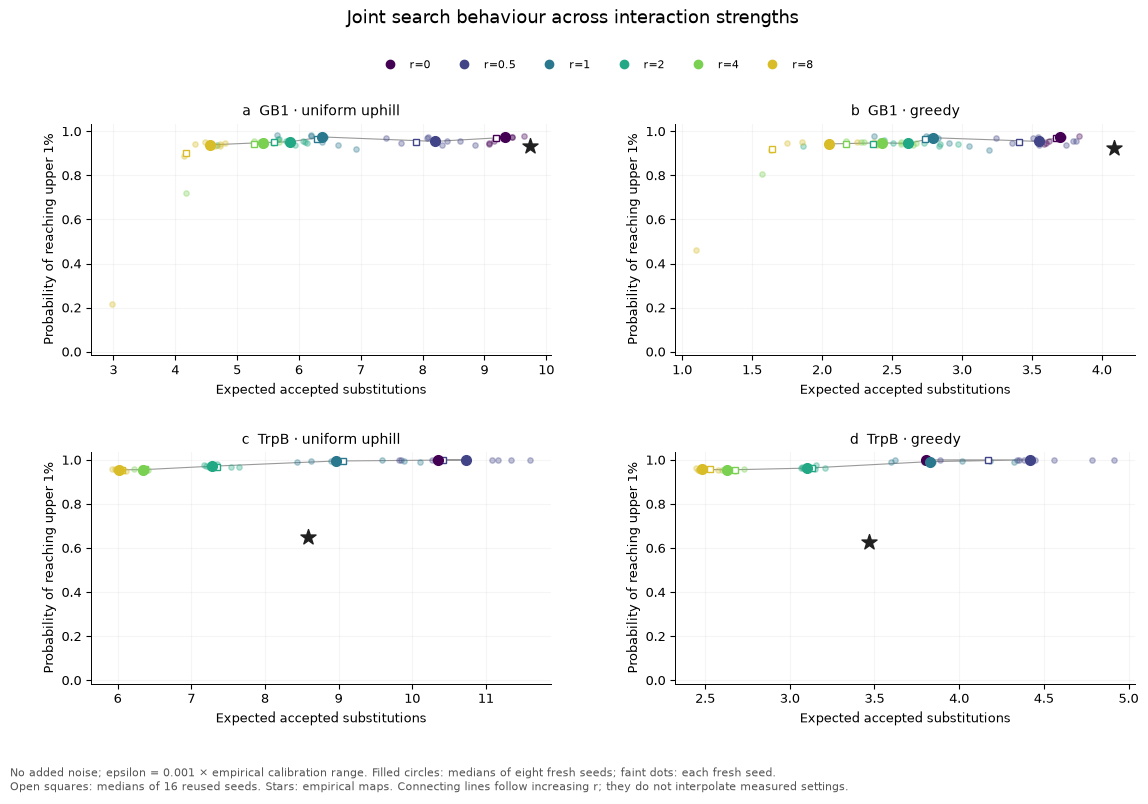

In [3]:
plots.tradeoff(graph, cubes, fits, latent, analysis.FIGURES)

## Figure 2 | The interaction knob trades search length against aggregate epistasis.

Lines show medians; blue bands show the 10th–90th percentiles across eight fresh seeds, not uncertainty intervals for an estimated population mean. Confirmation statistics use 32 empirical four-site binary cubes and eight fixed synthetic cube geometries per seed. WHT fractions are means over cubes with resolvable nonconstant power; order ≥2 is epistatic and order ≥3 is high-order. Sign epistasis is a face-level fraction. DR is the median fixed-direction mutation-effect versus background-fitness regression slope; the mean slope is also retained in the tables. Local SD was a calibration target on the calibration panel; these values describe its transfer to confirmation cubes.

At GB1 r=0.5, epistatic and high-order fractions are 0.546 and 0.162 versus empirical 0.555 and 0.179; median DR is −0.637 versus −0.690. However, mean local SD is 0.286 versus 0.108 (2.64-fold). This is useful shape resemblance with an amplitude mismatch, not uniform agreement. TrpB has a stronger trade-off: the noiseless r=1 setting that lengthens walks has epistatic fraction 0.264 versus 0.688.

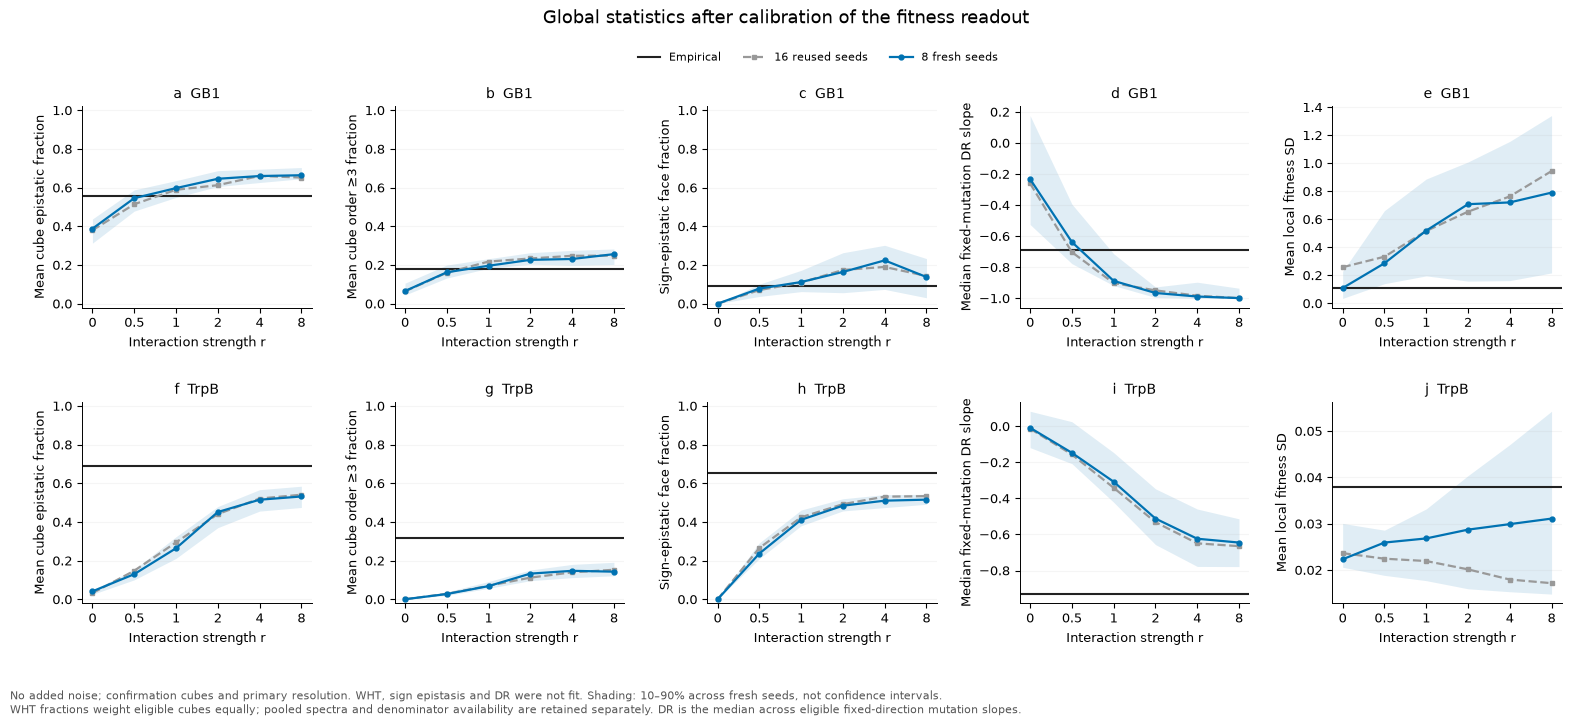

In [4]:
plots.epistasis(graph, cubes, fits, latent, analysis.FIGURES)

## Figure 3 | TrpB resemblance depends on the observation model.

Noise is frozen per genotype, shared across r through common random uniforms, and not redrawn at each visit. Each observation-aware setting is calibrated with its fixed noise pool. Dashed curves show that setting's intrinsic fitness map; solid curves show its observed map. Independent-difference noise and shared-stop sensitivity are explicit assumptions from RUN-172, not identified causes of empirical measurement error.

Shared-stop r=0.5 gives 7.46 substitutions, 71.4% upper-1% success, epistatic fraction 0.630, sign-epistatic fraction 0.656 and median DR −0.899. Empirical values are 8.59, 65.0%, 0.688, 0.651 and −0.931. This is a plausible coarse benchmark regime. But r=0 with this noise already produces much of the apparent epistasis, so agreement does not uniquely support an intrinsic interaction mechanism. Seed sensitivity matters: shared-stop r=4 success shifts from 70.1% for the 16 reused seeds to 87.5% for the eight fresh seeds.

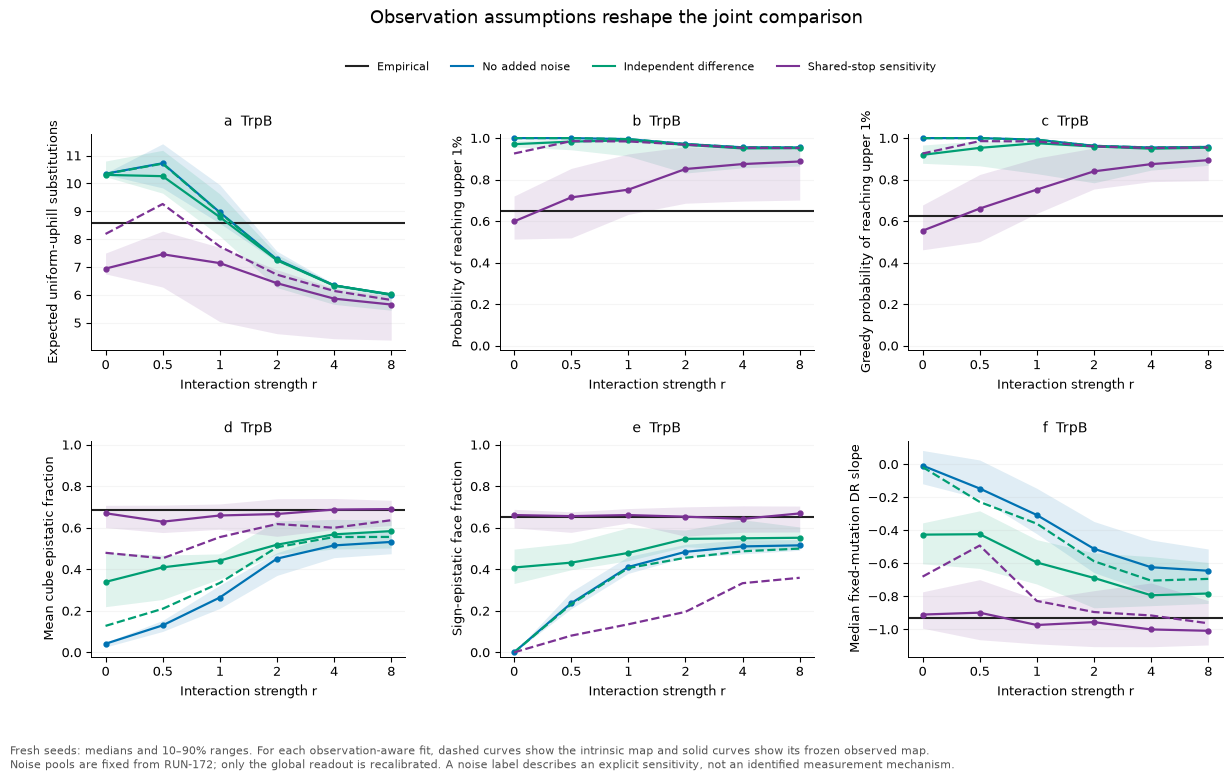

In [5]:
plots.observation(graph, cubes, fits, latent, analysis.FIGURES)

## Figure 4 | Resolution changes both walk outcomes and apparent neutrality.

Colored lines and bands are no-noise fresh-seed medians and 10–90% ranges at zero, 0.001 and 0.01 times the empirical calibration range. Matching dotted lines show the empirical values. Black dashed curves use the latent coordinate A+rG with strict ordering, isolating graph topology from finite-precision saturation of the sigmoid. Mathematical monotonicity does not guarantee that tiny fitness differences survive floating-point evaluation.

Neutral edges join nodes whose fitness difference is within tolerance. Components in the right column are calculated after excluding the empirical near-floor threshold, and normalized by retained above-floor nodes. Chains of individually small changes can span many tolerances; such components are not evidence for one conserved functional phenotype. Missing empirical genotypes are masked in the synthetic maps, not imputed.

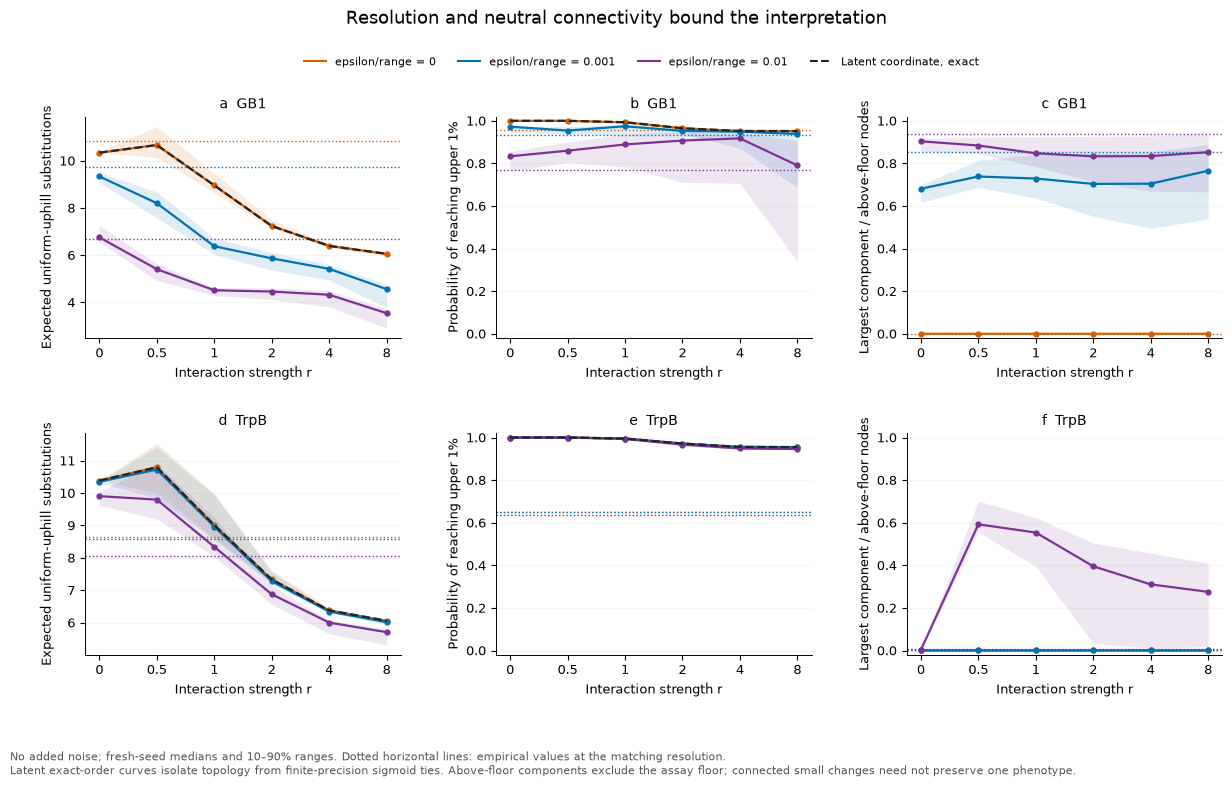

In [6]:
plots.sensitivity(graph, cubes, fits, latent, analysis.FIGURES)

## Figure 5 | Calibration fit and denominator availability constrain the comparison.

The finite differential-evolution budget was identical to the earlier protocol (60 iterations, population factor 8), with the frozen endpoint parameter vectors additionally considered at intermediate strengths. All optimizer records retain `converged=False`; these are finite-budget solutions, not established global optima. r=0 and r=4 are exact anchors, not newly optimized points. Quantiles, mean local SD and floor mass are the only calibration terms. A lower calibration objective need not improve unfit graph behavior.

The other panels show the fraction of cubes with resolvable WHT power and the fraction of fixed-direction mutation slopes that can be estimated. Near-flat or otherwise undefined statistics remain unavailable, rather than being replaced by zero. Raw per-seed values, pooled spectra, exact-best success and reachability are retained in the tables.

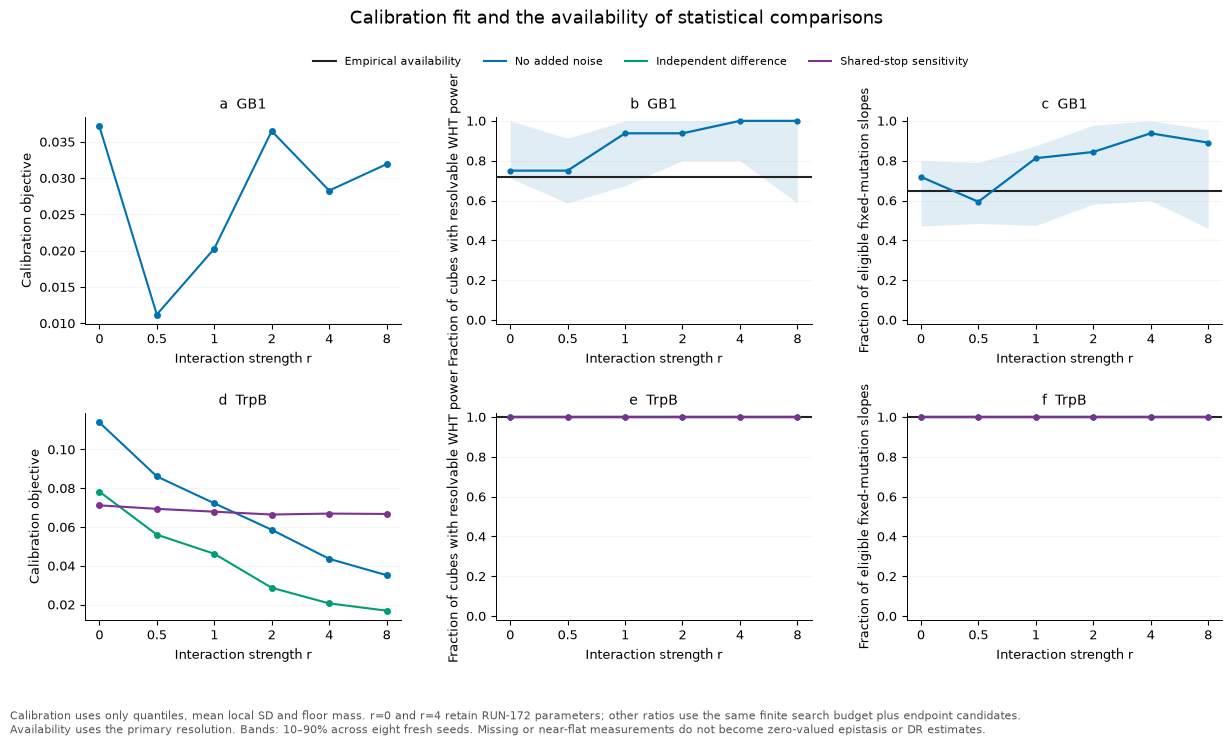

In [7]:
plots.calibration(graph, cubes, fits, latent, analysis.FIGURES)

## Interpretation and numerical reference

The sweep supports treating interaction strength as a meaningful benchmark control. It improves joint resemblance to GB1 at lower r and supplies observation-conditioned TrpB regimes with broadly empirical global statistics and nontrivial search. It does not show that strength alone can reproduce all TrpB behavior, that shared-stop noise is the true assay mechanism, or that a single parameter set works across assays.

For an online ML environment, the defensible result is a family of reproducible, partially empirical-looking regimes with disclosed differences. Eight fresh seeds reveal substantial generation variability; medians are not guarantees for individual landscapes. These are four-site, post-fit comparisons, with previously inspected empirical data. They do not establish biological realism at arbitrary sequence length or recover particular empirical interactions. The public model was not changed in this RUN.

The tables below preserve numerical values behind the main comparisons. `q10` and `q90` summarize between-seed variation. No hypothesis is accepted or rejected using an arbitrary threshold.

In [8]:
summary = pd.read_csv(analysis.TABLES / 'aggregate_estimates.csv')
key_metrics = ['uniform_steps', 'uniform_hit_top', 'epistatic_fraction', 'ho_fraction', 'slope_median', 'sign_epistasis_fraction', 'sd_fitness']
chosen = summary[summary.relative_resolution.eq(.001) & summary.metric.isin(key_metrics) & (
    summary.cohort.eq('empirical') |
    (summary.cohort.eq('fresh') & summary.protein.eq('GB1') & summary.observation.eq('none') & summary.ratio.eq(.5)) |
    (summary.cohort.eq('fresh') & summary.protein.eq('TrpB') & summary.observation.eq('shared_stop_sensitivity') & summary.layer.eq('observed') & summary.ratio.eq(.5)))]
chosen.to_csv(analysis.TABLES / 'key_comparisons.csv', index=False)
display(chosen[['protein','cohort','ratio','observation','metric','median','q10','q90']].round(4))

,protein,cohort,ratio,observation,metric,median,q10,q90
17,GB1,empirical,-1.0,measured,uniform_steps,9.7404,9.7404,9.7404
19,GB1,empirical,-1.0,measured,uniform_hit_top,0.9354,0.9354,0.9354
23,GB1,empirical,-1.0,measured,epistatic_fraction,0.5548,0.5548,0.5548
24,GB1,empirical,-1.0,measured,ho_fraction,0.1792,0.1792,0.1792
28,GB1,empirical,-1.0,measured,slope_median,-0.6898,-0.6898,-0.6898
29,GB1,empirical,-1.0,measured,sign_epistasis_fraction,0.0911,0.0911,0.0911
30,GB1,empirical,-1.0,measured,sd_fitness,0.1082,0.1082,0.1082
119,GB1,fresh,0.5,none,uniform_steps,8.2022,7.5805,8.6793
121,GB1,fresh,0.5,none,uniform_hit_top,0.9544,0.9382,0.9728
125,GB1,fresh,0.5,none,epistatic_fraction,0.5456,0.4788,0.5886


## Scientific context

Wu et al. (2016), *Adaptation in protein fitness landscapes is facilitated by indirect paths*, [eLife 5:e16965](https://doi.org/10.7554/eLife.16965), motivates distinguishing accessible paths from outcomes of a particular walk policy. Nowak and Krug (2015), *Analysis of adaptive walks on NK fitness landscapes with different interaction schemes*, [arXiv:1503.07796](https://arxiv.org/abs/1503.07796), connects interaction structure with walk behavior. Johnston et al. (2024), [PNAS, doi:10.1073/pnas.2400439121](https://doi.org/10.1073/pnas.2400439121), provides the TrpB experimental context. These papers frame the diagnostics; they do not validate this fitted model.